# Air raid alerts in Ukraine — exploratory data analysis

Goal: understand the alert process well enough to design a forecasting model — **data quality, trend,
seasonality (daily / weekly / monthly) and regional structure** — and to fix the data source and the modelling window.

**Summary of decisions made in this notebook**

| | decision | why |
|---|---|---|
| source | official alerts from [Vadimkin/ukrainian-air-raid-sirens-dataset](https://github.com/Vadimkin/ukrainian-air-raid-sirens-dataset) | the volunteer source is measurably unreliable since 2024 (section 1) |
| target unit | oblast; "alert" = any oblast- or raion-level alert in the oblast | hromada alerts are hyper-local front-line alerts |
| modelling window | **2025-11-01 → 2026-09-04 00:00 Kyiv** | raion-level alerting from Nov 2025; the yellow/red system started 4 Sep 2026 |

All timestamps are UTC in the data; daily patterns are shown in Kyiv local time.

In [1]:
import sys; sys.path.insert(0, "..")
%matplotlib inline
import pandas as pd
from ua_alerts import config, data, eda

data.download()                      # pass force=True to refresh
off = data.load_official()           # oblast + raion level, deduplicated, capped at 72 h
vol = data.load_volunteer()
cov, cov_v = eda.load_grids()        # hourly share of each hour under alert, per oblast
print(f"official : {len(off):,} alerts, last start {off.started_at.max()}")
print(f"volunteer: {len(vol):,} alerts, last start {vol.started_at.max()}")
print(f"official grid used: {cov.index.min()} .. {cov.index.max()} UTC, {cov.shape[1]} oblasts")

official : 164,615 alerts, last start 2026-09-07 05:28:22+00:00
volunteer: 115,784 alerts, last start 2026-10-10 04:47:44+00:00
official grid used: 2022-03-15 16:00:00+00:00 .. 2026-09-03 20:00:00+00:00 UTC, 24 oblasts


## 1. Data sources — what is usable for the latest period?

The task asks to evaluate on the latest period, so the first question was which source has reliable data up to now.

| source | data until | verdict |
|---|---|---|
| official (Vadimkin repo, parsed from Telegram [@air_alert_ua](https://t.me/s/air_alert_ua)) | **2026-09-07** — the channel itself stopped posting on 7 Sep 06:09 UTC ([open issue](https://github.com/Vadimkin/ukrainian-air-raid-sirens-dataset/issues/7)) | reliable, but stops |
| volunteer (eTryvoga, same repo; also behind air-alarms.in.ua) | today | **unreliable since 2024**, see below |
| raid.fly.dev / alerts.com.ua API | — | its documented source is the same stopped @air_alert_ua channel |
| regional administration Telegram channels | today | usable only for Lviv and Kyiv City; front-line ОВА channels post news, not alerts |
| alerts.in.ua | today, with yellow/red levels | history only via a token granted after manual review — not obtainable before the deadline |

On top of that, on **4 Sep 2026** Ukraine switched to a two-level (yellow = drones / red = missiles) alert system
(CabMin resolution №1092; [hromadske](https://hromadske.ua/en/ukraine/270469-ukraine-introduces-yellow-and-red-air-raid-alerts-to-distinguish-drone-and-missile-threats)).
Even with perfect data, alerts after that date mean something different and have no history to learn from.

### Is the volunteer source reliable?
Minute-level comparison with official alerts (official = oblast + raion level), summed over all oblasts:

In [2]:
eda.source_reliability(off, vol)

,volunteer_hours,official_hours,precision,recall
year,,,,
2022,13201.48,13341.30,0.95,0.94
2023,17783.38,16833.07,0.86,0.91
2024,21878.30,30297.18,0.89,0.64
2025,20429.03,42734.63,0.90,0.43
2026,14558.55,41065.37,0.87,0.31


Until 2023 the two sources agree (≈ 0.9+ both ways). From 2024 the volunteer data still rarely *invents* alerts
(precision ≈ 0.9), but it covers a shrinking share of official alert time: **31 % in 2026**. Further checks (in the AI log):
it almost never misses an alert entirely, but it **chops long alerts into short pieces** — it covers only 37 % of official
alerts longer than 4 h and produces many extra "starts" (only 34 % of its 2026 alert starts match an official start within 15 min).
It is worst exactly where alerts matter most — front-line oblasts (21–26 % recall) — and contains spurious alerts in Volyn and Lviv.

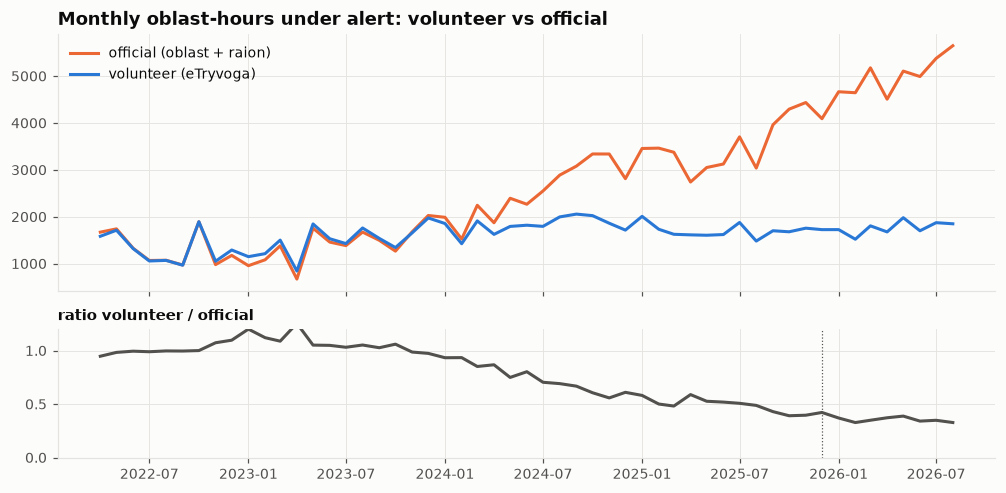

In [3]:
ratio = eda.plot_source_comparison(cov, cov_v)

**Decision.** Use the official data and stop at the start of the yellow/red system. The evaluation period is therefore
the last weeks before 4 Sep 2026 — the latest period in which "alert" has a stable meaning and reliable data exists.

**Cleaning** (`ua_alerts/data.py`): drop exact duplicate rows (≈ half of 2025 oblast-level rows were duplicated);
keep oblast- and raion-level alerts; cap alerts at 72 h (above the 99.9th percentile of raion alerts — multi-day front-line alerts are real);
drop Luhansk (permanent alert, re-added at prediction time together with Crimea). Overlapping alerts within an oblast
(several raions) are **unioned**, so the target is "some part of the oblast is under alert".

## 2. Trend and regional structure

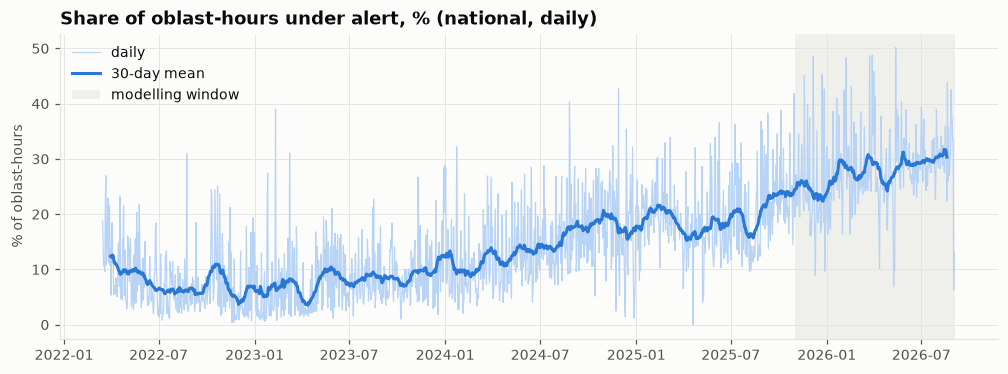

2022     7.900000
2023     8.000000
2024    14.400000
2025    20.299999
2026    28.500000
dtype: float32

In [4]:
daily = eda.plot_trend(cov)
daily.groupby(daily.index.year).mean().round(1)

The national share of oblast-hours under alert rose from ~8 % (2022–23) to ~28 % (2026). Part of this is real escalation
(it starts in 2024), part is definitional: since late 2025 alerts are raion-level, and "any raion of the oblast under alert"
is on more often than an oblast-wide alert used to be. This is why the model is trained only on the shaded window.

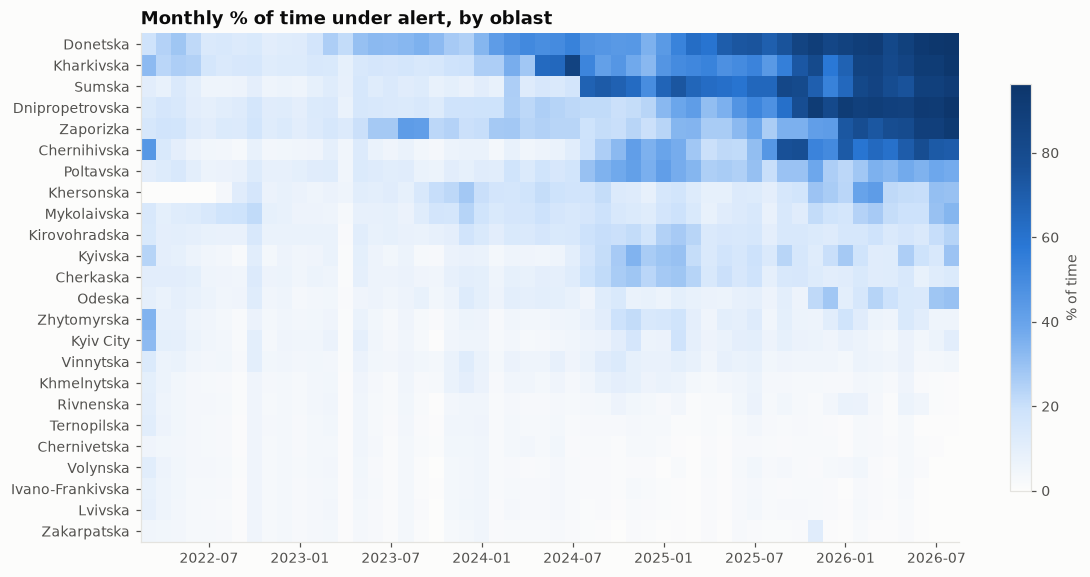

,Dnipropetrovska oblast,Donetska oblast,Kharkivska oblast,Sumska oblast,Zaporizka oblast,Chernihivska oblast,Poltavska oblast,Khersonska oblast,Mykolaivska oblast,Odeska oblast,...,Kyiv City,Vinnytska oblast,Rivnenska oblast,Khmelnytska oblast,Zakarpatska oblast,Volynska oblast,Chernivetska oblast,Ternopilska oblast,Lvivska oblast,Ivano-Frankivska oblast
% time under alert,89,89,82,77,73,65,33,28,23,20,...,6,5,4,3,2,2,2,2,1,1
% hours with any alert,96,95,93,89,86,78,50,45,42,38,...,13,9,6,5,3,4,3,3,3,3


In [5]:
eda.plot_oblast_month(cov)
w = eda.regime(cov)
pd.DataFrame({"% time under alert": w.mean() * 100, "% hours with any alert": (w > 0).mean() * 100}) \
  .sort_values("% time under alert", ascending=False).round(0).astype(int).T

In the modelling window the front-line oblasts (Donetsk, Kharkiv, Sumy, Dnipropetrovsk, Zaporizhzhia) are under alert
**73–89 % of the time** (any alert in 86–96 % of hours), the west 1–5 %. For the front line, "an alert in the next few hours" is almost certain,
so metrics must be reported **per oblast** — pooled metrics would be dominated by these easy cases.

## 3. Seasonality

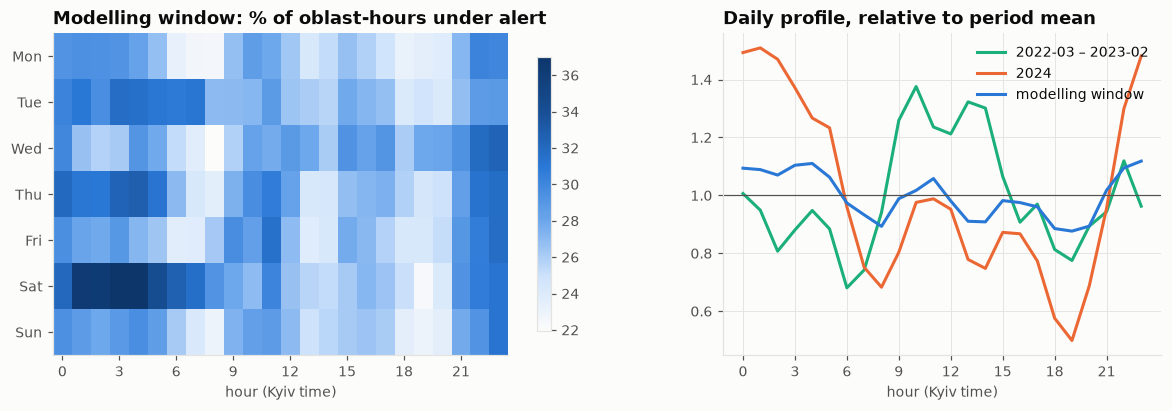

In [6]:
eda.plot_hour_weekday(cov)

* In the modelling window alerts are more likely **at night (22–06 h)** and least likely around 08 h and 18–20 h.
  The profile has changed over the war (daytime peaks in 2022–23, a strong night peak in 2024), so it should be learned from recent data.
* There is **no consistent day-of-week pattern** — rows of the heatmap differ by single heavy nights rather than by a weekly rhythm.

### STL / MSTL decomposition

* Daily national series, robust STL, period 7.
* Hourly national series in the modelling window, MSTL with periods 24 h and 168 h.

Seasonal strength $F_S = \max(0,\ 1 - \mathrm{Var}(R)/\mathrm{Var}(S+R))$ (Hyndman & Athanasopoulos, *FPP3* §4.3).

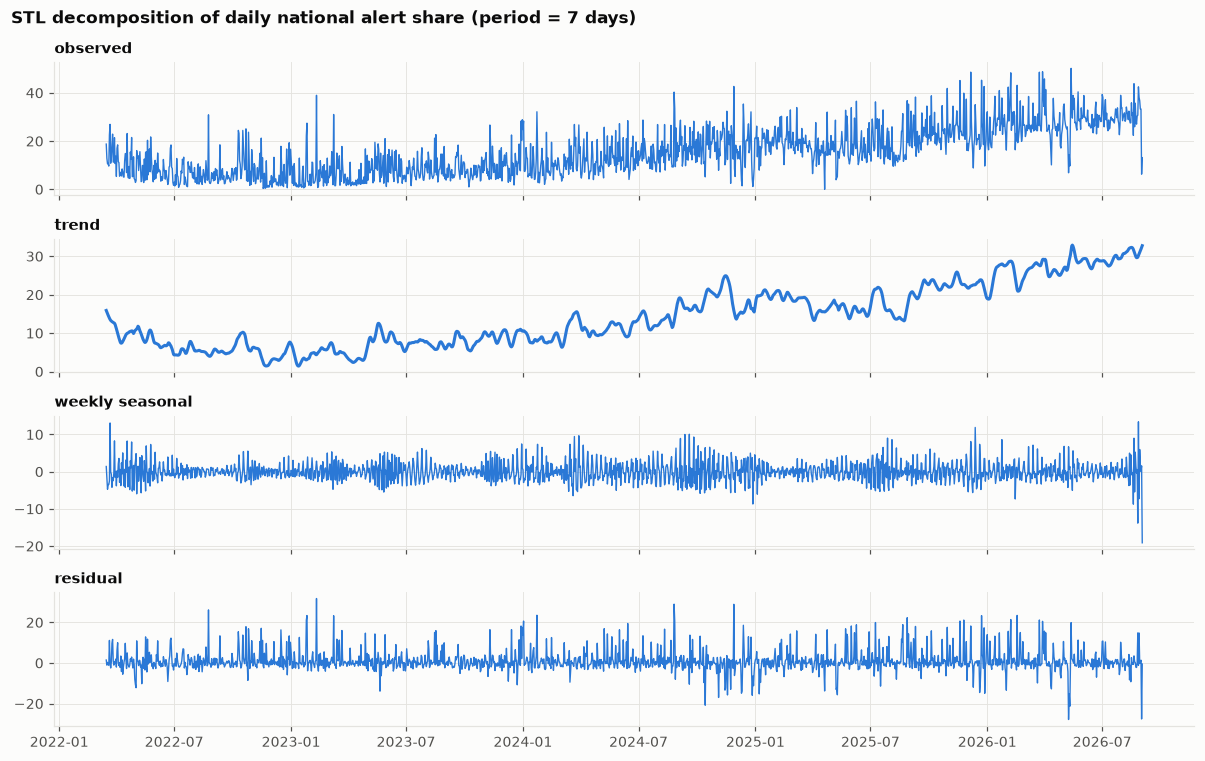

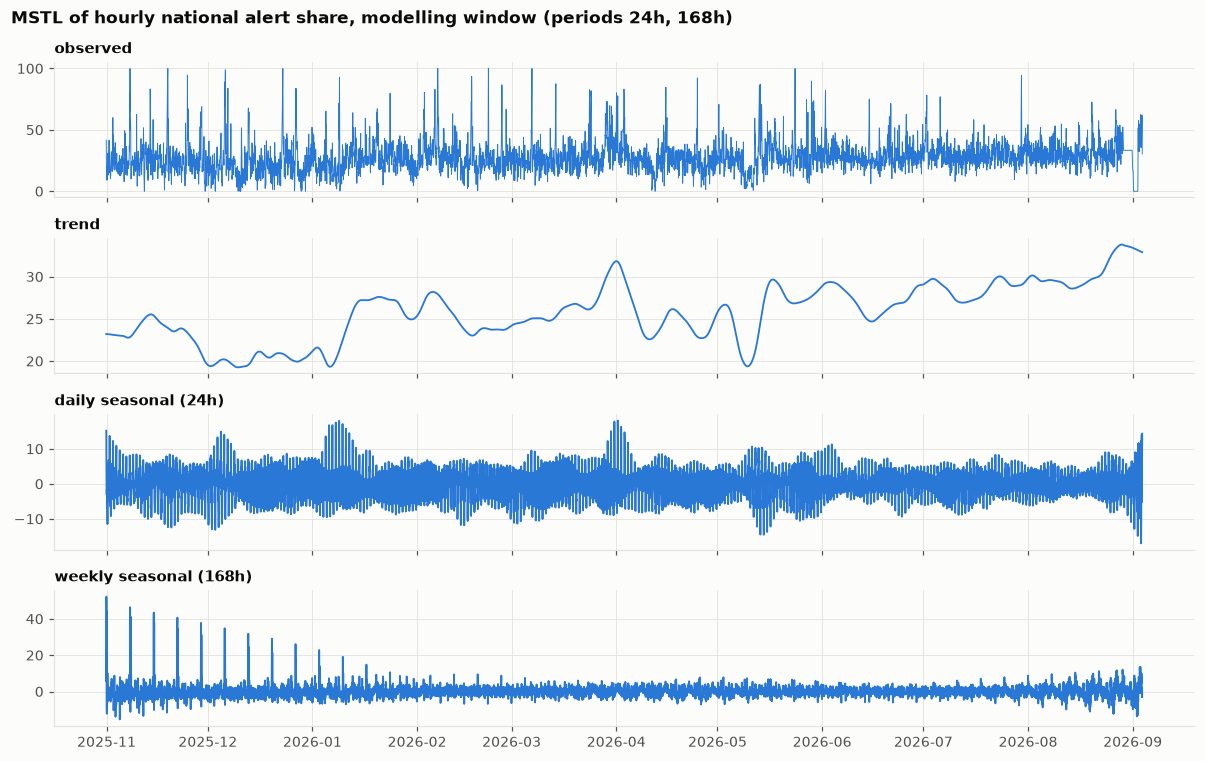

{'weekly_strength': np.float64(0.13),
 'trend_strength': np.float64(0.68),
 'daily_strength_hourly': np.float64(0.07),
 'weekly_strength_hourly': np.float64(0.03)}

In [7]:
stats = eda.plot_stl(daily, cov)
{k: round(v, 2) for k, v in stats.items()}

Weekly seasonality is weak (0.13 on the daily series, 0.03 on the hourly series), the 24 h component explains little
of the national hourly variance (0.07), while the **trend is strong (0.68)** — the dominant structure is the level shift, not cycles.
Spikes of the seasonal components at the edges of the MSTL plot are STL boundary artifacts.

### Daily seasonality per oblast

The national average mixes oblasts with different rhythms, so the daily cycle is measured per oblast with a fixed
hour-of-day profile: the *peak / trough ratio* (relative amplitude) and the *variance explained* by hour of day.
(A first attempt used per-oblast STL; it gave Zakarpattia the "strongest" seasonality despite a flat profile — STL's
time-varying seasonal component absorbed individual alert bursts — so it was replaced.)

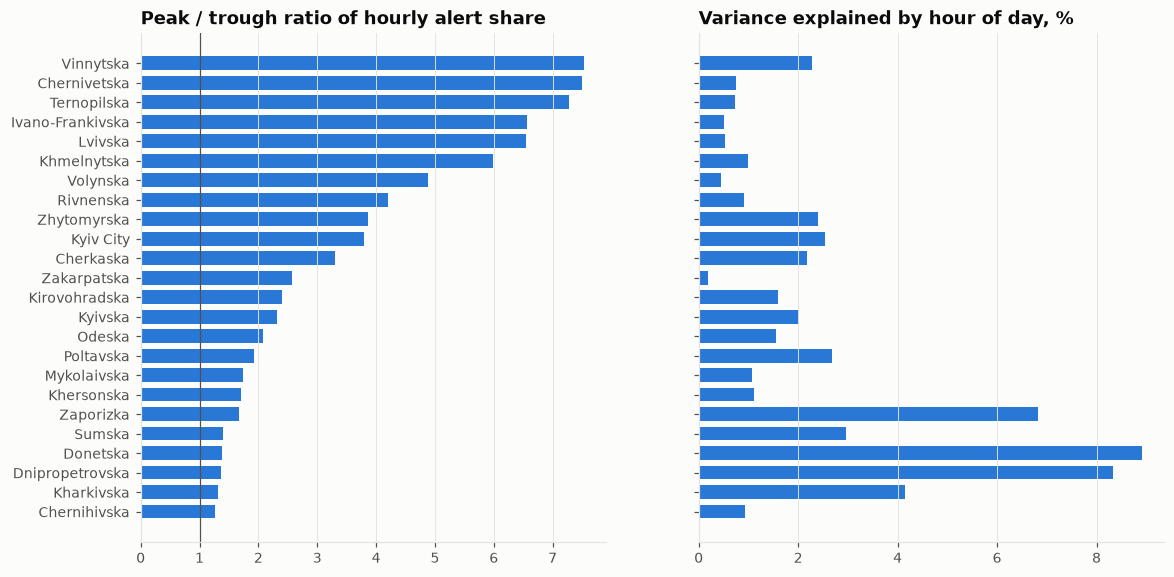

,Vinnytska oblast,Chernivetska oblast,Ternopilska oblast,Ivano-Frankivska oblast,Lvivska oblast,Khmelnytska oblast,Volynska oblast,Rivnenska oblast,Zhytomyrska oblast,Kyiv City,...,Odeska oblast,Poltavska oblast,Mykolaivska oblast,Khersonska oblast,Zaporizka oblast,Sumska oblast,Donetska oblast,Dnipropetrovska oblast,Kharkivska oblast,Chernihivska oblast
eta2,0.023,0.007,0.007,0.005,0.005,0.010,0.004,0.009,0.024,0.025,...,0.016,0.027,0.011,0.011,0.068,0.03,0.089,0.083,0.042,0.009
peak_trough,7.525,7.502,7.274,6.565,6.543,5.982,4.877,4.205,3.863,3.790,...,2.073,1.931,1.731,1.707,1.669,1.39,1.387,1.370,1.316,1.260
peak_hour,1.000,3.000,5.000,5.000,6.000,2.000,7.000,5.000,6.000,3.000,...,1.000,0.000,23.000,23.000,11.000,21.00,11.000,11.000,22.000,22.000


In [8]:
by_oblast = eda.plot_daily_strength_by_oblast(cov)
by_oblast.astype(float).round(3).sort_values("peak_trough", ascending=False).T

**The daily cycle is large in relative terms but explains little variance.** In western and central oblasts the alert
share at the peak hour (night, 01–07 h) is **4–7.5× higher** than at the quietest hour; on the front line only 1.3–1.7×,
with a *daytime* peak (11 h). Yet hour of day explains only 0.2–9 % of the hourly variance — whether an alert episode is
in progress matters far more than the clock. → hour of day is a useful **multiplier of the base rate**, especially in the rear, not a predictor on its own.

### Monthly seasonality?

A ~30-day cycle would show up as an ACF peak near lag 30 of the detrended daily series and a dominant periodogram peak near 30 days.

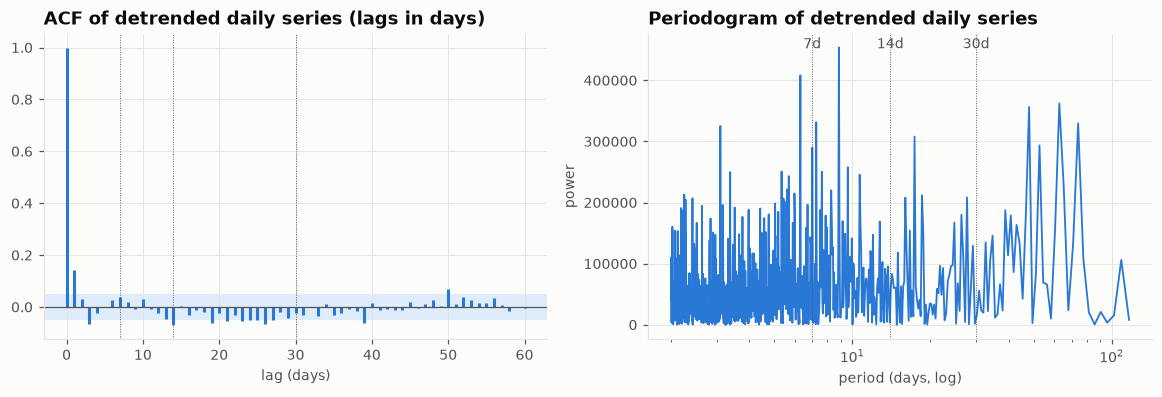

In [9]:
eda.plot_acf_periodogram(daily)

**No evidence of monthly seasonality.** The ACF is significant only at lag 1 (≈ 0.14 — busy days cluster); lags 7, 14 and 30
are inside the 95 % band, and the periodogram has no dominant peak. Month-of-year effects cannot be estimated from ~4.5 years anyway.

## 4. Regional dependence — does a neighbour's alert predict mine?

Plain lift $P(X_{t+1} \mid Y_t)\,/\,P(X_{t+1})$ in the modelling window:

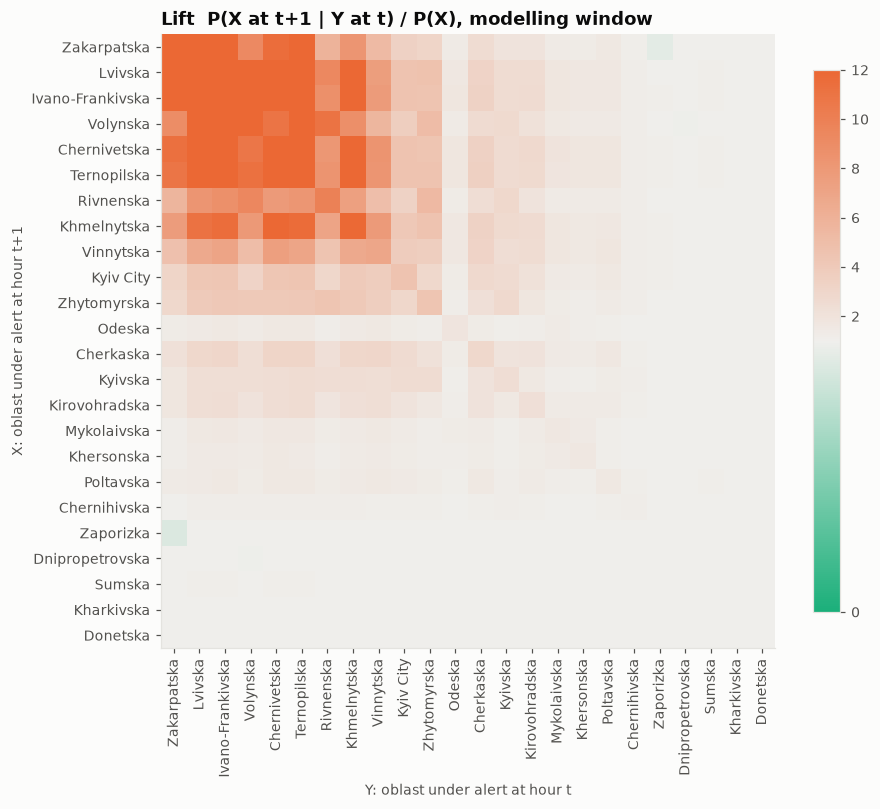

In [10]:
lift = eda.plot_lift(cov)

Plain lift is high and nearly symmetric for western oblasts — it mostly captures *simultaneity* (the west goes on alert
together during massive strikes) and persistence. To test whether an alert in Y **precedes** a new alert in X, condition on X being quiet:

$$\text{onset lift}(X, Y) = \frac{P(X \text{ starts at } t{+}1 \mid X \text{ quiet at } t,\ Y \text{ active at } t)}{P(X \text{ starts at } t{+}1 \mid X \text{ quiet at } t)}$$

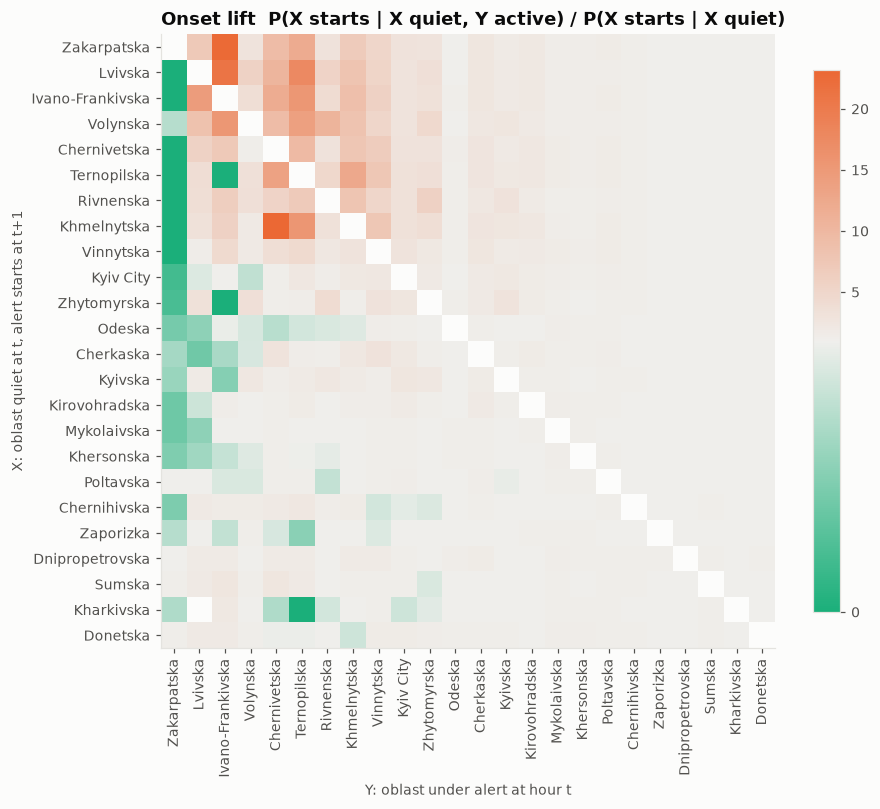

Khmelnytska oblast       Chernivetska oblast        23.2
Zakarpatska oblast       Ivano-Frankivska oblast    22.7
Lvivska oblast           Ivano-Frankivska oblast    21.0
                         Ternopilska oblast         17.5
Khmelnytska oblast       Ternopilska oblast         15.5
Volynska oblast          Ivano-Frankivska oblast    15.3
Ivano-Frankivska oblast  Ternopilska oblast         15.3
                         Lvivska oblast             14.5
Volynska oblast          Ternopilska oblast         14.0
Ternopilska oblast       Chernivetska oblast        13.6
dtype: float64

In [11]:
onset = eda.plot_onset_lift(cov)
onset.stack().sort_values(ascending=False).head(10).round(1)

**Alerts propagate between rear oblasts.** When a western oblast (Ivano-Frankivsk, Ternopil, Chernivtsi, Khmelnytskyi) is under alert,
a quiet neighbour is 10–23× more likely to start an alert within the next hour. For front-line oblasts the lift is ≈ 1 — they are on
alert regardless. Rear oblasts have few alerts, so individual pair values are noisy; the model should get **aggregated regional state**
(e.g. share of western / central / front-line oblasts under alert, national share) rather than 24×24 pairwise features.

## 5. Conclusions for modelling

1. **Data**: official alerts, oblast level (union of oblast + raion alerts); window 2025-11-01 → 2026-09-04 (Kyiv). Luhansk & Crimea are
   permanent alerts — added to the output, excluded from metrics.
2. **Target**: P(oblast is under alert at some point in the next *h* hours), *h* = 3 (also 1 and 6); evaluation on the last 5 weeks
   before 4 Sep with a rolling-origin backtest.
3. **Metrics per oblast** — front-line oblasts are on alert 73–89 % of the time and would dominate pooled metrics.
4. **Features**: own current state and recent history (persistence dominates), regional/national state (propagation in the rear),
   hour of day in Kyiv time (relative amplitude up to 7×). Day of week and month: no evidence they help.
5. **Baselines** to beat: persistence (alert now → alert soon), per-oblast hour-of-day rate.